In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1. EXISTING ENRICHMENT RESULTS — searching for Wnt terms
  no existing enrichment file mentions Wnt

2. ENRICHMENT OF THE FIVE HUB GENES
  terms returned: 121

  --- top 12 terms overall ---
                  Gene_set                                                                Term Overlap  P-value  Adjusted P-value  Combined Score                    Genes
    WikiPathway_2023_Human ncRNAs Involved In Wnt Signaling In Hepatocellular Carcinoma WP4336    5/85      0.0               0.0    2.730727e+06 DKK4;WNT6;FZD3;FZD6;FZD9
    WikiPathway_2023_Human      lncRNA In Canonical Wnt Signaling And Colorectal Cancer WP4258    5/93      0.0               0.0    2.683821e+06 DKK4;WNT6;FZD3;FZD6;FZD9
    WikiPathway_2023_Human                                                 Wnt Signaling WP428   5/114      0.0               0.0    2.577739e+06 DKK4;WNT6;FZD3;FZD6;F

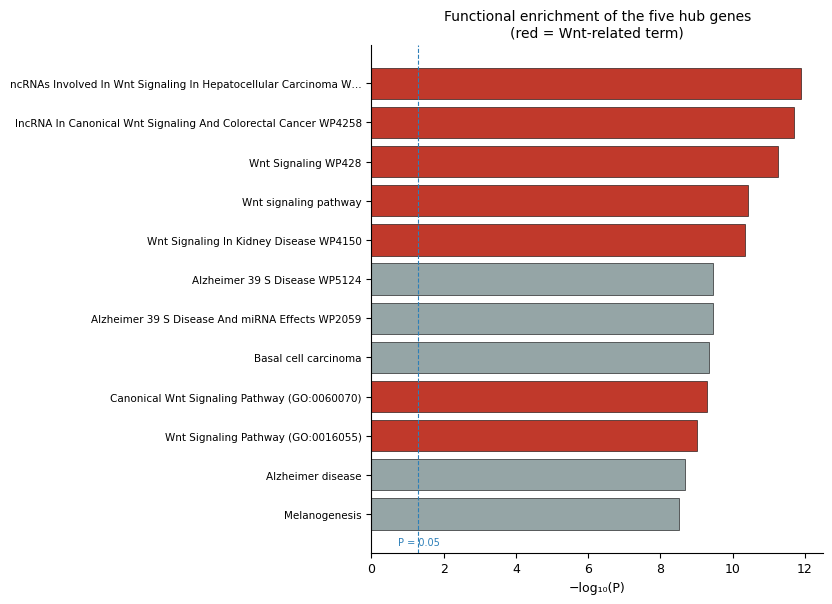


SUMMARY
                            Item                                                Value
                       Hub genes                         WNT6, FZD9, DKK4, FZD6, FZD3
   Existing files mentioning Wnt                                                    0
   Wnt-related terms (hub genes)                                                   24
Wnt terms with adjusted P < 0.05                                                   24
                  Interpretation Hub gene selection is supported at the pathway level

Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Pathway/


In [2]:
# ===== HUB GENE PATHWAY VALIDATION — Wnt signalling support =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q gseapy statsmodels", shell=True)
import os, glob, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
import gseapy as gp
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
OUT  = ROOT + "Final/HubGene_Pathway/"
FIG, TAB = OUT+"Figures/", OUT+"Tables/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB): os.makedirs(d, exist_ok=True)

HUB    = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
COMMON = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
          "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
ALL_G  = list(dict.fromkeys(COMMON + HUB))
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ---------- 1. search existing enrichment output for Wnt ----------
print("="*78+"\n1. EXISTING ENRICHMENT RESULTS — searching for Wnt terms\n"+"="*78)
hits = []
for f in glob.glob(ROOT+"**/*.csv", recursive=True) + glob.glob(ROOT+"**/*.txt", recursive=True):
    if os.path.getsize(f) > 5_000_000: continue
    try: txt = open(f, errors="ignore").read(400_000)
    except Exception: continue
    if "Wnt" in txt or "WNT" in txt:
        low = os.path.basename(f).lower()
        if any(k in low for k in ("enrich","kegg","go_","reactome","pathway","gsea","metascape")):
            hits.append(f)
if hits:
    print(f"  enrichment files mentioning Wnt: {len(hits)}")
    for f in hits[:10]:
        print(f"\n  {f.replace(ROOT,'')}")
        try:
            d = pd.read_csv(f)
            tc = next((c for c in d.columns if "term" in c.lower()
                       or "descrip" in c.lower() or "name" in c.lower()), d.columns[0])
            w = d[d[tc].astype(str).str.contains("wnt", case=False, na=False)]
            show = [c for c in d.columns if c in (tc,) or
                    any(k in c.lower() for k in ("p-value","pvalue","adjust","fdr","q-value",
                                                 "combined","odds","genes","overlap"))]
            if len(w): print(w[show].head(5).to_string(index=False))
            else: print("     (term column has no Wnt row)")
        except Exception as e:
            print(f"     could not parse: {e}")
else:
    print("  no existing enrichment file mentions Wnt")

# ---------- 2. fresh enrichment on the hub genes ----------
print("\n"+"="*78+"\n2. ENRICHMENT OF THE FIVE HUB GENES\n"+"="*78)
LIBS = ["KEGG_2021_Human","Reactome_2022","WikiPathway_2023_Human",
        "GO_Biological_Process_2023","MSigDB_Hallmark_2020"]
try:
    enr = gp.enrichr(gene_list=HUB, gene_sets=LIBS, organism="human",
                     outdir=None, no_plot=True)
    R = enr.results.copy()
    R = R[["Gene_set","Term","Overlap","P-value","Adjusted P-value",
           "Combined Score","Genes"]].sort_values("P-value")
    R.to_csv(TAB+"Table_hub_enrichment_full.csv", index=False)
    print(f"  terms returned: {len(R)}")
    print("\n  --- top 12 terms overall ---")
    print(R.head(12).round(5).to_string(index=False))
    W = R[R.Term.str.contains("wnt|frizzled|beta-catenin|beta catenin",
                              case=False, na=False)]
    W.to_csv(TAB+"Table_hub_Wnt_terms.csv", index=False)
    print(f"\n  --- Wnt-related terms: {len(W)} ---")
    if len(W):
        print(W.head(15).round(5).to_string(index=False))
        sig = W[W["Adjusted P-value"] < 0.05]
        print(f"\n  Wnt terms with adjusted P < 0.05: {len(sig)}/{len(W)}")
        if len(sig):
            best = sig.iloc[0]
            print(f"  strongest: {best.Term} ({best.Gene_set})")
            print(f"    overlap {best.Overlap}, adjusted P = {best['Adjusted P-value']:.2e}")
            print(f"    genes: {best.Genes}")
    else:
        print("  none — report the hub genes by family membership instead")
except Exception as e:
    print(f"  enrichr failed ({e}); check network access")
    R = pd.DataFrame()

# ---------- 3. enrichment of the full 16-gene panel, for contrast ----------
print("\n"+"="*78+"\n3. ENRICHMENT OF THE FULL PANEL (16 genes)\n"+"="*78)
try:
    enr2 = gp.enrichr(gene_list=ALL_G, gene_sets=LIBS, organism="human",
                      outdir=None, no_plot=True)
    R2 = enr2.results[["Gene_set","Term","Overlap","P-value","Adjusted P-value",
                       "Combined Score","Genes"]].sort_values("P-value")
    R2.to_csv(TAB+"Table_panel_enrichment_full.csv", index=False)
    sig2 = R2[R2["Adjusted P-value"] < 0.05]
    print(f"  terms returned: {len(R2)} | adjusted P < 0.05: {len(sig2)}")
    print("\n  --- top 12 ---")
    print(R2.head(12).round(5).to_string(index=False))
    W2 = R2[R2.Term.str.contains("wnt|frizzled|beta-catenin", case=False, na=False)]
    print(f"\n  Wnt-related terms in the full panel: {len(W2)}")
    if len(W2): print(W2.head(8).round(5).to_string(index=False))
except Exception as e:
    print(f"  enrichr failed ({e})")
    R2 = pd.DataFrame()

# ---------- 4. figure ----------
if len(R):
    top = R.head(12).copy()
    top["logP"] = -np.log10(top["P-value"].clip(lower=1e-300))
    top["isWnt"] = top.Term.str.contains("wnt|frizzled|beta-catenin",
                                         case=False, na=False)
    top = top.sort_values("logP")
    fig, ax = plt.subplots(figsize=(8.4, .36*len(top)+1.8))
    ax.barh(range(len(top)), top.logP,
            color=np.where(top.isWnt, "#c0392b", "#95a5a6"),
            edgecolor="black", lw=.4)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([t[:62]+("…" if len(t)>62 else "") for t in top.Term], fontsize=7.5)
    ax.axvline(-np.log10(0.05), ls="--", c="#2c7fb8", lw=.8)
    ax.text(-np.log10(0.05), -0.8, "P = 0.05", fontsize=7, color="#2c7fb8", ha="center")
    ax.set_xlabel("−log₁₀(P)")
    ax.set_title("Functional enrichment of the five hub genes\n"
                 "(red = Wnt-related term)", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG+"Fig_hub_enrichment.png", dpi=600, bbox_inches="tight")
    fig.savefig(FIG+"Fig_hub_enrichment.pdf", bbox_inches="tight")
    plt.show()

# ---------- 5. summary ----------
nW = len(W) if 'W' in dir() and len(R) else 0
nWs = len(W[W["Adjusted P-value"]<0.05]) if nW else 0
rep = pd.DataFrame({"Item":[
    "Hub genes","Existing files mentioning Wnt","Wnt-related terms (hub genes)",
    "Wnt terms with adjusted P < 0.05","Interpretation"],
  "Value":[", ".join(HUB), len(hits), nW, nWs,
    ("Hub gene selection is supported at the pathway level"
     if nWs else "Report hub genes by gene-family membership rather than enrichment")]})
rep.to_csv(TAB+"Table_summary.csv", index=False)
print("\n"+"="*78+"\nSUMMARY\n"+"="*78)
print(rep.to_string(index=False))
print("\nSaved ->", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA
  GSE14390: 42904 probes x 7 samples (3 exposed / 4 control)
  GSE12131: 42904 probes x 4 samples (2 exposed / 2 control)

  combined: n=11 (5 exposed / 6 control), 20848 gene symbols
  hub genes present: 5/5

1. PER-GENE DISCRIMINATION (no model fitted)
Gene   AUC  CI_low  CI_high  Cohens_d  t_test_P  Wilcoxon_P         Direction  t_test_FDR
WNT6 0.967   0.800    1.000     2.068     0.011       0.009 Higher in exposed       0.056
FZD9 0.733   0.400    1.000     0.722     0.298       0.247 Higher in exposed       0.649
FZD3 0.667   0.267    1.000     0.522     0.432       0.429 Higher in exposed       0.649
FZD6 0.600   0.200    1.000     0.414     0.519       0.662 Higher in exposed       0.649
DKK4 0.533   0.167    0.867    -0.134     0.830       0.931  Lower in exposed       0.830

2. SINGLE-GENE GSEA ON CO-EXPRESSED GENES
  genes ranked by Spearman c

2026-10-22 16:56:59,239 [WARNING] Duplicated values found in preranked stats: 99.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


  WNT6: 5181 sets tested | FDR < 0.25: 691
      NES +2.45  FDR 0.000  GO_Biological_Process_2023__Positive Regulation Of Tyrosine Ph
      NES +2.41  FDR 0.000  GO_Biological_Process_2023__Regulation Of Tyrosine Phosphoryla
      NES +2.40  FDR 0.000  Reactome_2022__Interleukin-10 Signaling R-HSA-6783783


2026-10-22 17:05:22,423 [WARNING] Duplicated values found in preranked stats: 99.00% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


  FZD9: 5180 sets tested | FDR < 0.25: 113
      NES +2.60  FDR 0.000  Reactome_2022__Eukaryotic Translation Elongation R-HSA-156842
      NES +2.60  FDR 0.000  Reactome_2022__Peptide Chain Elongation R-HSA-156902
      NES +2.54  FDR 0.000  Reactome_2022__Selenocysteine Synthesis R-HSA-2408557


...

  DKK4: 5181 sets tested | FDR < 0.25: 201
      NES +2.07  FDR 0.213  GO_Biological_Process_2023__DNA-templated DNA Replication Main
      NES -1.44  FDR 0.236  KEGG_2021_Human__Phagosome
      NES -1.45  FDR 0.225  KEGG_2021_Human__Thyroid cancer


2026-10-22 17:21:50,964 [WARNING] Duplicated values found in preranked stats: 99.00% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


  FZD6: 5181 sets tested | FDR < 0.25: 126
      NES +2.95  FDR 0.000  Reactome_2022__Selenocysteine Synthesis R-HSA-2408557
      NES +2.94  FDR 0.000  Reactome_2022__GTP Hydrolysis And Joining Of 60S Ribosomal Sub
      NES +2.93  FDR 0.000  Reactome_2022__L13a-mediated Translational Silencing Of Cerulo


2026-10-22 17:30:02,537 [WARNING] Duplicated values found in preranked stats: 99.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


  FZD3: 5180 sets tested | FDR < 0.25: 103
      NES +2.38  FDR 0.001  Reactome_2022__Interferon Alpha/Beta Signaling R-HSA-909733
      NES +2.17  FDR 0.007  Reactome_2022__Interferon Gamma Signaling R-HSA-877300
      NES +2.15  FDR 0.006  Reactome_2022__Endosomal/Vacuolar Pathway R-HSA-1236977

  total significant sets across hub genes (FDR < 0.25): 1234

SUMMARY
Hub_gene  Sets_tested  Sig_FDR025                                                                         Top_term  Top_NES
    WNT6         5181         691 GO_Biological_Process_2023__Positive Regulation Of Tyrosine Phosphorylation Of S    2.453
    FZD9         5180         113                    Reactome_2022__Eukaryotic Translation Elongation R-HSA-156842    2.602
    DKK4         5181         201 GO_Biological_Process_2023__DNA-templated DNA Replication Maintenance Of Fidelit    2.070
    FZD6         5181         126                            Reactome_2022__Selenocysteine Synthesis R-HSA-2408557    2.951
    FZD3   

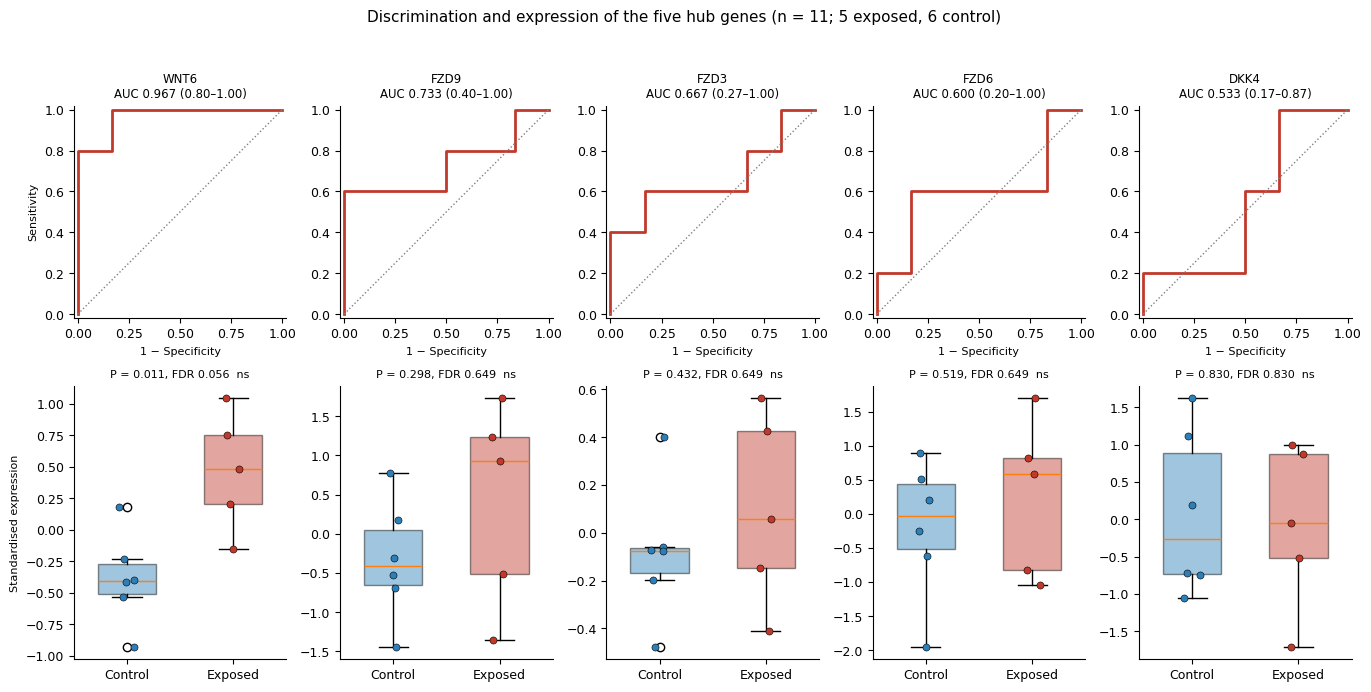

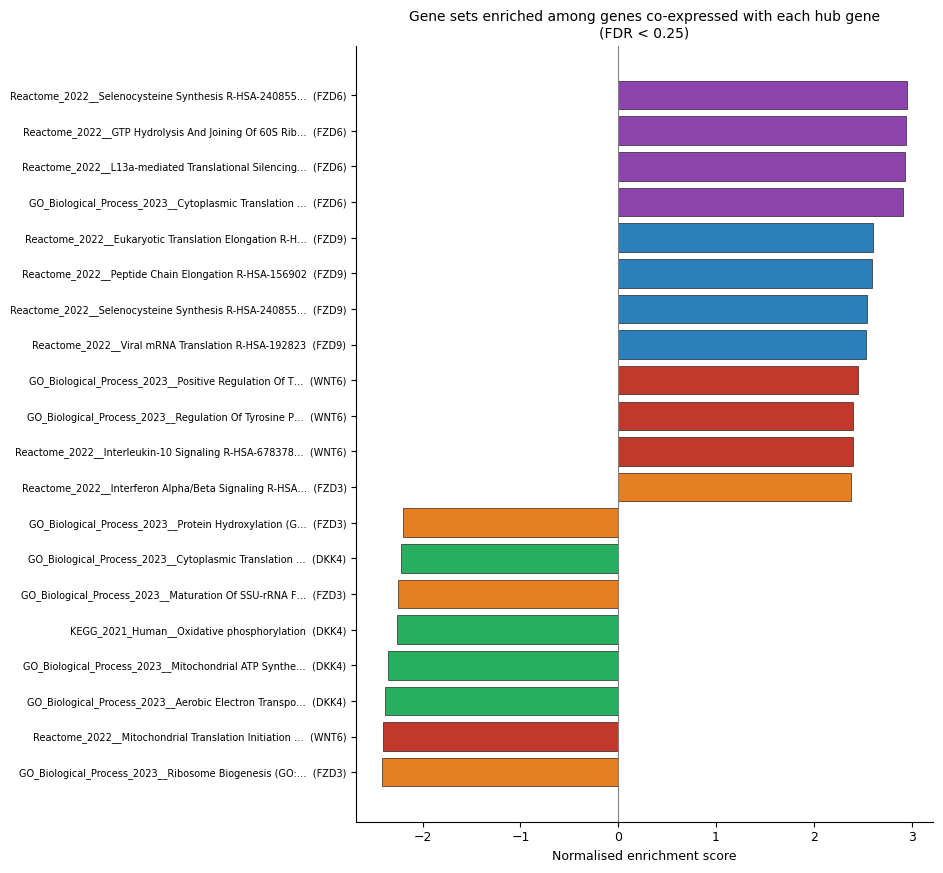


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Validation/


In [3]:
# ===== HUB GENE VALIDATION — per-gene ROC/boxplot + single-gene GSEA =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q gseapy scikit-learn statsmodels", shell=True)
import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
import gseapy as gp
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/HubGene_Validation/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

FILES = {"GSE14390": DATA+"GSE14390_matrix_Transpose_labeled.csv",
         "GSE12131": DATA+"GSE12131_matrix_Transpose_labeled.csv"}
HUB = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
GSEA_LIBS = ["KEGG_2021_Human","GO_Biological_Process_2023","Reactome_2022"]
N_BOOT, MIN_SIZE, MAX_SIZE, SEED = 2000, 10, 500, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def gcols(g, cols):
    p = re.compile(rf"^{re.escape(g)}(\.\d+)?$", re.IGNORECASE)
    return [c for c in cols if p.match(str(c).strip())]

print("="*78+"\nDATA\n"+"="*78)
frames, ys, origins = [], [], []
for name, path in FILES.items():
    df = pd.read_csv(path)
    yv = df.pop("target").values.astype(int)
    X = df.apply(pd.to_numeric, errors="coerce")
    X = X.loc[:, X.notna().any()]
    X = X.loc[:, ~X.columns.astype(str).str.contains("///", regex=False)]
    if float(np.nanmax(X.values)) > 50: X = np.log2(X.clip(lower=0)+1)
    X = (X - X.mean())/X.std(ddof=0).replace(0,1)
    frames.append(X); ys.append(yv); origins += [name]*len(yv)
    print(f"  {name}: {X.shape[1]} probes x {len(yv)} samples "
          f"({yv.sum()} exposed / {(1-yv).sum()} control)")
y = np.concatenate(ys); origin = np.array(origins)
n1, n0 = int(y.sum()), int((1-y).sum())

shared = sorted(set(frames[0].columns) & set(frames[1].columns))
FULL = pd.concat([f[shared] for f in frames], ignore_index=True)
FULL.columns = [re.sub(r"\.\d+$", "", c) for c in FULL.columns]
FULL = FULL.T.groupby(level=0).mean().T          # collapse probes to symbols
print(f"\n  combined: n={len(y)} ({n1} exposed / {n0} control), "
      f"{FULL.shape[1]} gene symbols")
hub = [g for g in HUB if g in FULL.columns]
print(f"  hub genes present: {len(hub)}/5")

# =============== 1. PER-GENE ROC AND EXPRESSION ===============
print("\n"+"="*78+"\n1. PER-GENE DISCRIMINATION (no model fitted)\n"+"="*78)
rng = np.random.RandomState(SEED)
i0, i1 = np.where(y==0)[0], np.where(y==1)[0]
rows = []
for g in hub:
    v = FULL[g].values
    a_ = roc_auc_score(y, v); flip = a_ < 0.5
    score = -v if flip else v
    auc = roc_auc_score(y, score)
    boots = [roc_auc_score(y[i], score[i]) for i in
             (np.concatenate([rng.choice(i0,len(i0)), rng.choice(i1,len(i1))])
              for _ in range(N_BOOT))]
    a, c = v[y==1], v[y==0]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    rows.append(dict(Gene=g, AUC=auc,
        CI_low=np.percentile(boots,2.5), CI_high=np.percentile(boots,97.5),
        Cohens_d=(a.mean()-c.mean())/sp if sp>0 else np.nan,
        t_test_P=stats.ttest_ind(a,c,equal_var=False).pvalue,
        Wilcoxon_P=stats.mannwhitneyu(a,c,alternative="two-sided").pvalue,
        Direction="Lower in exposed" if flip else "Higher in exposed"))
R = pd.DataFrame(rows)
R["t_test_FDR"] = multipletests(R.t_test_P, method="fdr_bh")[1]
R = R.sort_values("AUC", ascending=False)
R.round(4).to_csv(TAB+"Table_hub_per_gene_ROC.csv", index=False)
print(R.round(3).to_string(index=False))

fig, axes = plt.subplots(2, len(hub), figsize=(2.75*len(hub), 7.0))
for j, g in enumerate(R.Gene):
    r = R[R.Gene==g].iloc[0]
    v = FULL[g].values
    score = -v if r.Direction.startswith("Lower") else v
    f_, t_, _ = roc_curve(y, score)
    ax = axes[0, j]
    ax.plot(f_, t_, c="#c0392b", lw=2); ax.plot([0,1],[0,1], ":", c="grey", lw=1)
    ax.set_xlim(-.02,1.02); ax.set_ylim(-.02,1.02); ax.set_aspect("equal")
    ax.set_title(f"{g}\nAUC {r.AUC:.3f} ({r.CI_low:.2f}–{r.CI_high:.2f})", fontsize=8.5)
    if j == 0: ax.set_ylabel("Sensitivity", fontsize=8)
    ax.set_xlabel("1 − Specificity", fontsize=8)
    ax = axes[1, j]
    bp = ax.boxplot([v[y==0], v[y==1]], widths=.55, patch_artist=True,
                    tick_labels=["Control","Exposed"])
    for p_, c_ in zip(bp["boxes"], ["#2c7fb8","#c0392b"]):
        p_.set_facecolor(c_); p_.set_alpha(.45)
    for grp, xpos, c_ in [(0,1,"#2c7fb8"), (1,2,"#c0392b")]:
        pts = v[y==grp]
        ax.scatter(np.full(len(pts), xpos) + rng.uniform(-.08,.08,len(pts)), pts,
                   c=c_, s=26, edgecolor="black", lw=.4, zorder=3)
    star = ("***" if r.t_test_FDR<.001 else "**" if r.t_test_FDR<.01
            else "*" if r.t_test_FDR<.05 else "ns")
    ax.set_title(f"P = {r.t_test_P:.3f}, FDR {r.t_test_FDR:.3f}  {star}", fontsize=8)
    if j == 0: ax.set_ylabel("Standardised expression", fontsize=8)
fig.suptitle("Discrimination and expression of the five hub genes "
             f"(n = {len(y)}; {n1} exposed, {n0} control)", fontsize=11)
fig.tight_layout(rect=[0,0,1,.95])
fig.savefig(FIG+"Fig_hub_ROC_boxplot.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_hub_ROC_boxplot.pdf", bbox_inches="tight")

# =============== 2. SINGLE-GENE GSEA ===============
print("\n"+"="*78+"\n2. SINGLE-GENE GSEA ON CO-EXPRESSED GENES\n"+"="*78)
print("  genes ranked by Spearman correlation with each hub gene,")
print("  independent of group labels and of the PPI network\n")
all_res, summary = [], []
for g in hub:
    v = FULL[g].values
    rho = FULL.apply(lambda col: stats.spearmanr(col.values, v)[0], axis=0)
    rnk = rho.drop(labels=[g], errors="ignore").dropna().sort_values(ascending=False)
    rnk = rnk.to_frame().reset_index(); rnk.columns = [0, 1]
    try:
        pre = gp.prerank(rnk=rnk, gene_sets=GSEA_LIBS, permutation_num=1000,
                         min_size=MIN_SIZE, max_size=MAX_SIZE, seed=SEED,
                         outdir=None, threads=4, no_plot=True)
        d = pre.res2d.copy()
        d.columns = [c.strip() for c in d.columns]
        fdr_c = next(c for c in d.columns if "FDR" in c or "fdr" in c)
        nes_c = next(c for c in d.columns if "NES" in c)
        d["Hub_gene"] = g
        d[fdr_c] = pd.to_numeric(d[fdr_c], errors="coerce")
        d[nes_c] = pd.to_numeric(d[nes_c], errors="coerce")
        sig = d[d[fdr_c] < 0.25].sort_values(nes_c, ascending=False)
        all_res.append(d)
        print(f"  {g}: {len(d)} sets tested | FDR < 0.25: {len(sig)}")
        if len(sig):
            for _, r_ in sig.head(3).iterrows():
                print(f"      NES {r_[nes_c]:+.2f}  FDR {r_[fdr_c]:.3f}  "
                      f"{str(r_['Term'])[:62]}")
        summary.append(dict(Hub_gene=g, Sets_tested=len(d), Sig_FDR025=len(sig),
                            Top_term=str(sig.Term.iloc[0])[:80] if len(sig) else "",
                            Top_NES=round(sig[nes_c].iloc[0],3) if len(sig) else np.nan))
    except Exception as e:
        print(f"  {g}: GSEA failed ({e})")
        summary.append(dict(Hub_gene=g, Sets_tested=0, Sig_FDR025=0,
                            Top_term="failed", Top_NES=np.nan))

if all_res:
    A = pd.concat(all_res, ignore_index=True)
    A.to_csv(SUP+"TableS_single_gene_GSEA_full.csv", index=False)
    fdr_c = next(c for c in A.columns if "FDR" in c or "fdr" in c)
    nes_c = next(c for c in A.columns if "NES" in c)
    S = A[A[fdr_c] < 0.25].sort_values([nes_c], ascending=False)
    S.to_csv(TAB+"Table_single_gene_GSEA_significant.csv", index=False)
    print(f"\n  total significant sets across hub genes (FDR < 0.25): {len(S)}")

    if len(S):
        top = (S.sort_values(nes_c, key=abs, ascending=False)
                 .groupby("Hub_gene").head(4))
        top = top.sort_values([nes_c])
        figG, ax = plt.subplots(figsize=(9.5, .34*len(top)+2))
        cmap = {g: c for g, c in zip(hub, ["#c0392b","#2c7fb8","#27ae60",
                                           "#8e44ad","#e67e22"])}
        ax.barh(range(len(top)), top[nes_c],
                color=[cmap[g] for g in top.Hub_gene], edgecolor="black", lw=.4)
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels([f"{t[:52]}{'…' if len(t)>52 else ''}  ({g})"
                            for t, g in zip(top.Term.astype(str), top.Hub_gene)],
                           fontsize=7)
        ax.axvline(0, c="grey", lw=.8)
        ax.set_xlabel("Normalised enrichment score")
        ax.set_title("Gene sets enriched among genes co-expressed with each hub gene\n"
                     "(FDR < 0.25)", fontsize=10)
        figG.tight_layout()
        figG.savefig(FIG+"Fig_hub_GSEA.png", dpi=600, bbox_inches="tight")
        figG.savefig(FIG+"Fig_hub_GSEA.pdf", bbox_inches="tight")

SM = pd.DataFrame(summary)
SM.to_csv(TAB+"Table_GSEA_summary.csv", index=False)
print("\n"+"="*78+"\nSUMMARY\n"+"="*78)
print(SM.to_string(index=False))
print(f"\n  per-gene AUC range: {R.AUC.min():.3f} – {R.AUC.max():.3f}")
print(f"  hub genes with FDR < 0.05: {int((R.t_test_FDR<0.05).sum())}/{len(R)}")
plt.show(); print("\nSaved ->", OUT)